<a href="https://colab.research.google.com/github/Chow376/Project-399/blob/main/309.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
from pathlib import Path
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import os
import json
import h5py

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import pandas as pd

dfemg = pd.read_json('/content/drive/MyDrive/DATA /NICK/emg.json')
dfsub = pd.read_json('/content/drive/MyDrive/DATA /NICK/emg B.json')
dfevents = pd.read_json('/content/drive/MyDrive/DATA /NICK/events.jsonl', lines=True)

# Read session.json using a Series or standard dict
with open('/content/drive/MyDrive/DATA /NICK/session.json', 'r') as f:
    session_data = json.load(f)
dfsession = pd.Series(session_data)

def read_jrnl_with_nan(file_path):
    records = []
    with open(file_path, 'r', encoding='latin-1') as f:
        for line in f:
            line = line.strip()
            if line:
                try:
                    # Parse using native json loads and append valid records
                    records.append(json.loads(line))
                except json.JSONDecodeError:
                    # Skip lines that are not valid JSON (e.g. metadata header lines)
                    continue
    return pd.DataFrame(records)

# Read .jrnl files parsing with native json module and ignoring non-JSON rows
dftringo = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/tringo.jrnl')
dftreadmill = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/treadmill.jrnl')
dfpolar = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/polar.jrnl')

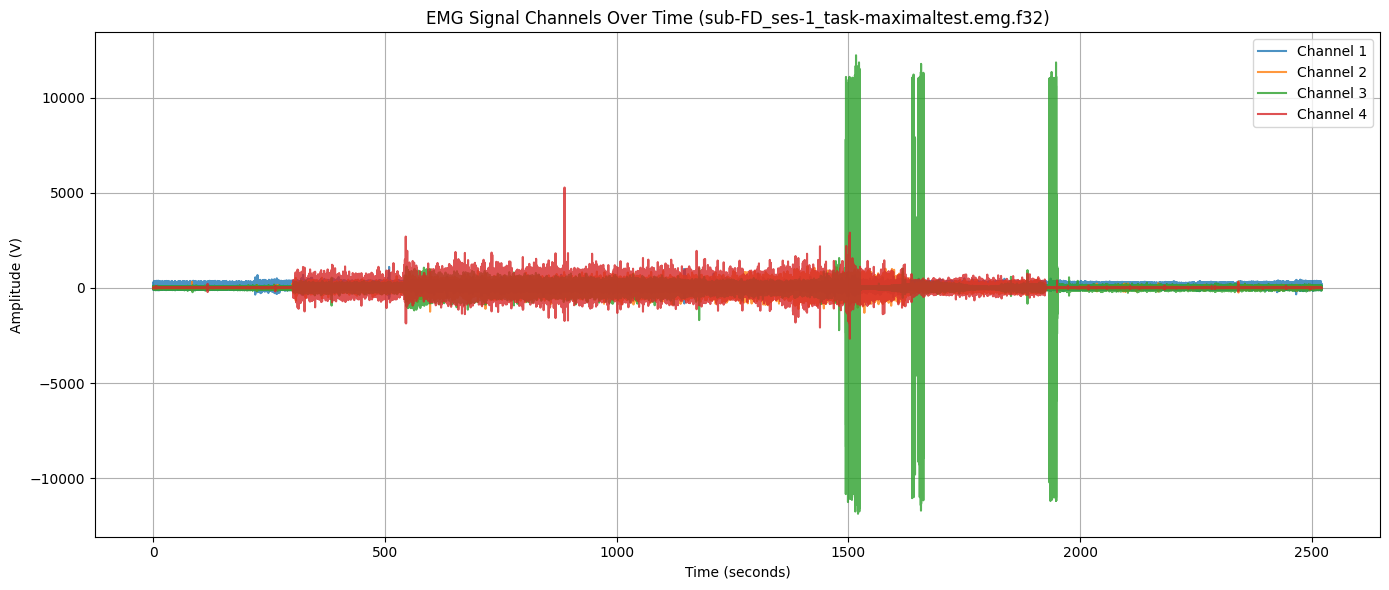

Successfully found and plotted: /content/drive/MyDrive/DATA /NICK/sub-FD_ses-1_task-maximaltest.emg.f32


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Restore built-in print if it was overridden
try:
    if 'print' in globals() and isinstance(globals()['print'], pd.DataFrame):
        del globals()['print']
except Exception:
    pass

# Let's extract file metadata from dfemg (or dfemgB if dfemg doesn't yield it)
emg_meta = dfemg.iloc[0]
binary_filename = emg_meta['file']
sample_rate = int(emg_meta.get('sample_rate', 2000))

# Recursively search for any .f32 file in Google Drive to find the data file
binary_path = None
search_root = '/content/drive/MyDrive/'

# First try to find the exact filename
for root, dirs, files in os.walk(search_root):
    if binary_filename in files:
        binary_path = os.path.join(root, binary_filename)
        break

# If not found by exact name, look for any .f32 file in Drive
if not binary_path:
    for root, dirs, files in os.walk(search_root):
        for f in files:
            if f.endswith('.f32'):
                binary_path = os.path.join(root, f)
                binary_filename = f
                break
        if binary_path:
            break

if binary_path and os.path.exists(binary_path):
    # Read the little-endian float32 binary file
    raw_emg = np.fromfile(binary_path, dtype='<f4')

    # Reshape based on number of active channels
    num_channels = len(dfemg)

    if len(raw_emg) % num_channels == 0:
        # Reshape to (samples, channels) since it is interleaved
        emg_data = raw_emg.reshape(-1, num_channels)

        # Create a time axis in seconds
        duration = len(emg_data) / sample_rate
        time_axis = np.linspace(0, duration, len(emg_data))

        # Plot the first few channels to keep the plot readable
        plt.figure(figsize=(14, 6))
        channels_to_plot = min(num_channels, 4)
        for ch in range(channels_to_plot):
            plt.plot(time_axis, emg_data[:, ch], label=f"Channel {ch + 1}", alpha=0.8)

        plt.title(f'EMG Signal Channels Over Time ({binary_filename})')
        plt.xlabel('Time (seconds)')
        plt.ylabel('Amplitude (V)')
        plt.legend(loc='upper right')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

        print(f"Successfully found and plotted: {binary_path}")
    else:
        # Try reshaping with other standard channel configurations (e.g. 4, 8, 16)
        resolved = False
        for possible_ch in [4, 8, 16, 2]:
            if len(raw_emg) % possible_ch == 0:
                emg_data = raw_emg.reshape(-1, possible_ch)
                duration = len(emg_data) / sample_rate
                time_axis = np.linspace(0, duration, len(emg_data))

                plt.figure(figsize=(14, 6))
                for ch in range(min(possible_ch, 4)):
                    plt.plot(time_axis, emg_data[:, ch], label=f"Channel {ch + 1}", alpha=0.8)
                plt.title(f'EMG Signal Channels Over Time ({binary_filename} - assumed {possible_ch} ch)')
                plt.xlabel('Time (seconds)')
                plt.ylabel('Amplitude (V)')
                plt.legend(loc='upper right')
                plt.grid(True)
                plt.tight_layout()
                plt.show()
                resolved = True
                print(f"Successfully plotted using auto-detected {possible_ch} channels.")
                break
        if not resolved:
            print(f"Binary data size ({len(raw_emg)}) could not be mapped to common channel dimensions.")
else:
    print(f"Could not locate any raw EMG (.f32) file in {search_root}. Please ensure the file is uploaded to your Google Drive.")

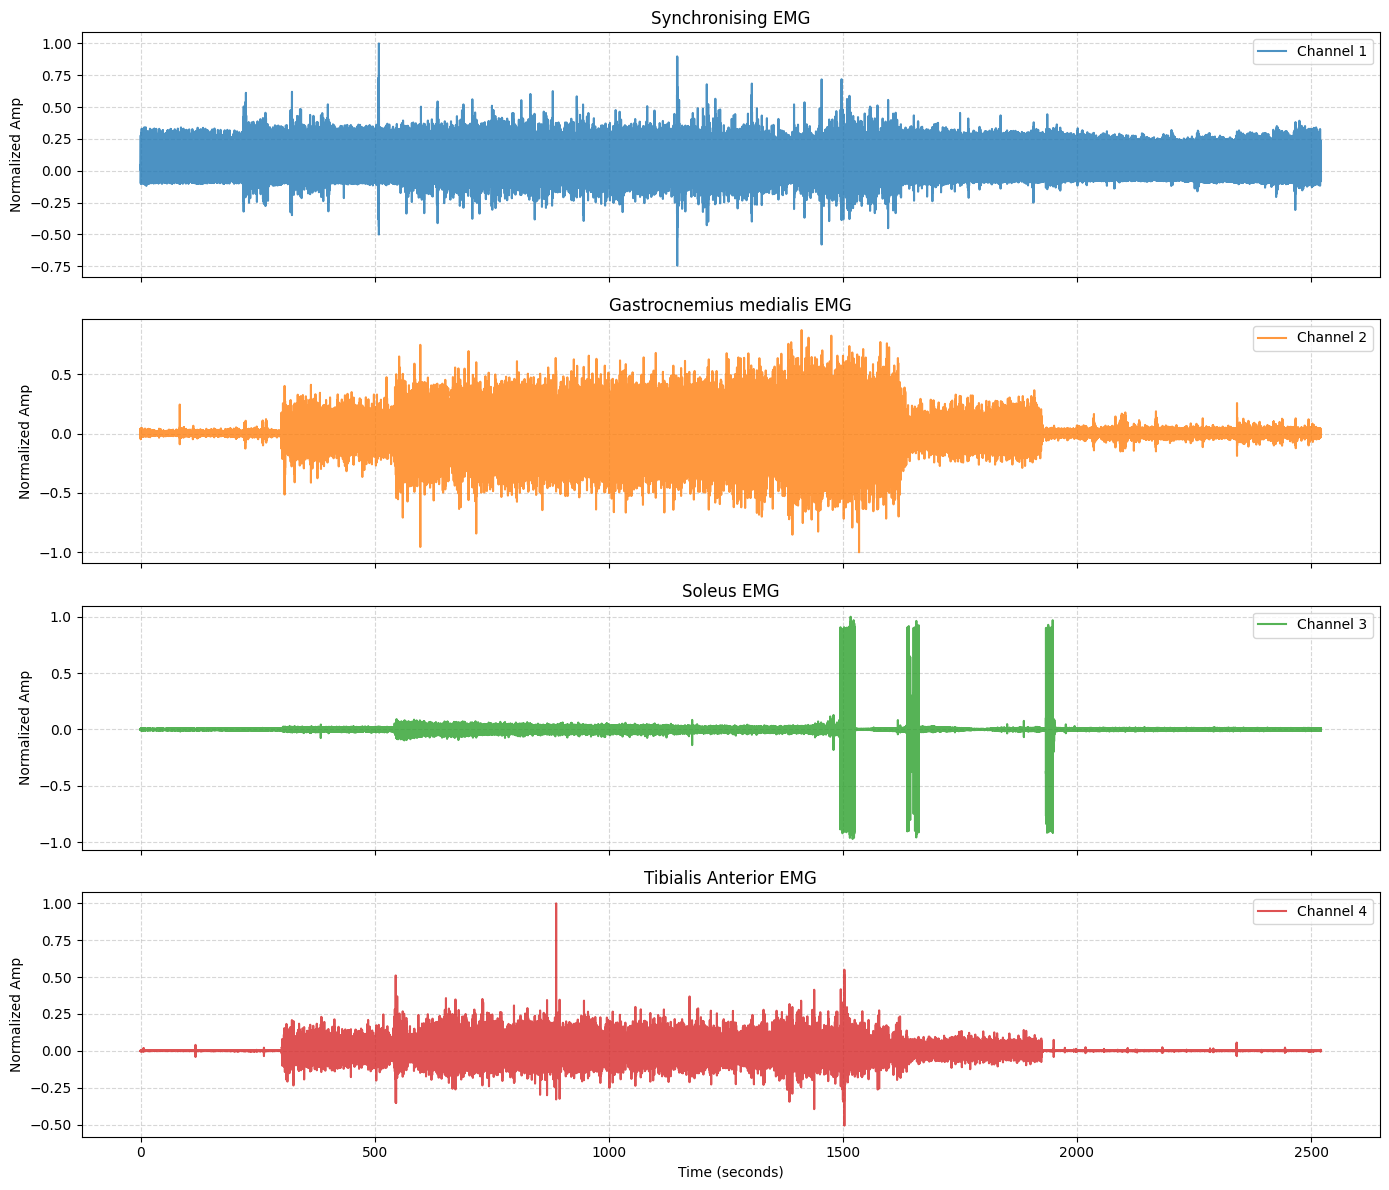

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Ensure we have the channel labels from dfemg metadata if available
try:
    # Map index/channel index to muscle/label names
    channel_names = dfemg['label'].tolist()
except Exception:
    channel_names = [f'Channel {i+1}' for i in range(num_channels)]

# Let's normalize the EMG signals (z-score normalization or min-max normalization)
# Here we will perform min-max normalization to scale amplitudes between -1 and 1
normalized_emg = np.zeros_like(emg_data)
for ch in range(num_channels):
    max_val = np.max(np.abs(emg_data[:, ch]))
    if max_val > 0:
        normalized_emg[:, ch] = emg_data[:, ch] / max_val
    else:
        normalized_emg[:, ch] = emg_data[:, ch]

# Plot each EMG channel on separate subplots
fig, axes = plt.subplots(num_channels, 1, figsize=(14, 3 * num_channels), sharex=True)
if num_channels == 1:
    axes = [axes]

for ch in range(num_channels):
    axes[ch].plot(time_axis, normalized_emg[:, ch], label=channel_names[ch], color=f'C{ch}', alpha=0.8)
    axes[ch].set_ylabel('Normalized Amp')
    axes[ch].grid(True, linestyle='--', alpha=0.5)
    axes[ch].legend(loc='upper right')

    axes[0].set_title('Synchronising EMG')
    axes[1].set_title('Gastrocnemius medialis EMG')
    axes[2].set_title('Soleus EMG')
    axes[3].set_title('Tibialis Anterior EMG')

axes[-1].set_xlabel('Time (seconds)')
plt.tight_layout()
plt.show()
#1= 7th rib heart 2= 3= 4=

To Do


*   Plot on seperate graphs
*   Label axis with correct EMG
normalise data







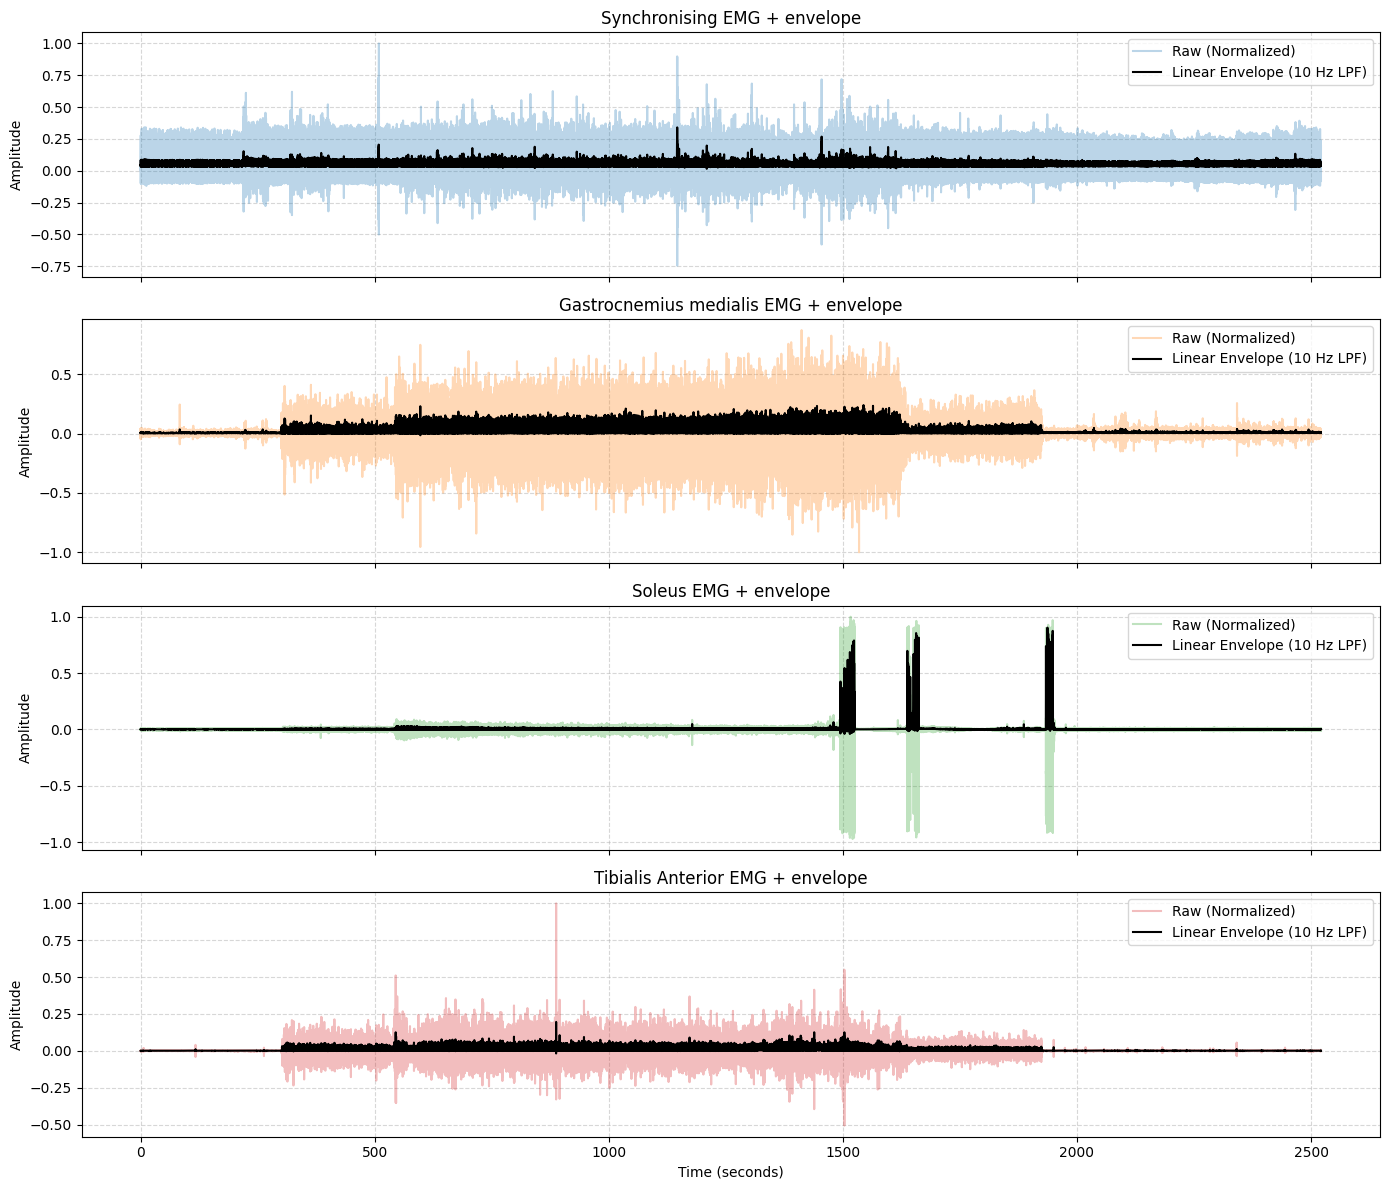

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

# Define a low-pass filter function to create the linear envelope
def lowpass_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y

# Parameters for envelope detection
cutoff_freq = 10.0  # Cutoff frequency in Hz for muscle contraction envelopes
fs = sample_rate    # Sampling frequency (2000 Hz)

# Ensure we have the channel labels
try:
    channel_names = dfemg['label'].tolist()
except Exception:
    channel_names = [f'Channel {i+1}' for i in range(num_channels)]

fig, axes = plt.subplots(num_channels, 1, figsize=(14, 3 * num_channels), sharex=True)
if num_channels == 1:
    axes = [axes]

for ch in range(num_channels):
    # 1. Full-wave rectification
    rectified_signal = np.abs(normalized_emg[:, ch])

    # 2. Low-pass filtering to obtain the linear envelope
    envelope = lowpass_filter(rectified_signal, cutoff_freq, fs, order=4)

    # Plot normalized raw EMG, rectified signal, and the linear envelope
    axes[ch].plot(time_axis, normalized_emg[:, ch], label='Raw (Normalized)', color=f'C{ch}', alpha=0.3)
    axes[ch].plot(time_axis, envelope, label='Linear Envelope (10 Hz LPF)', color='black', linewidth=1.5)

    axes[ch].set_ylabel('Amplitude')
    axes[0].set_title('Synchronising EMG + envelope')
    axes[1].set_title('Gastrocnemius medialis EMG + envelope')
    axes[2].set_title('Soleus EMG + envelope')
    axes[3].set_title('Tibialis Anterior EMG + envelope')

    axes[ch].grid(True, linestyle='--', alpha=0.5)
    axes[ch].legend(loc='upper right')

axes[-1].set_xlabel('Time (seconds)')
plt.tight_layout()
plt.show()

In [18]:
dfpolar = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/polar.jrnl')
dftringo = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/tringo.jrnl')
dftreadmill = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/treadmill.jrnl')
dfCPET = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/CPET__D_F_2026.10.09_15.46.34_.xml')
dfCPET2 = read_jrnl_with_nan('/content/drive/MyDrive/DATA /NICK/CPET__D_Nick_2026.10.09_13.53.57_.xml')

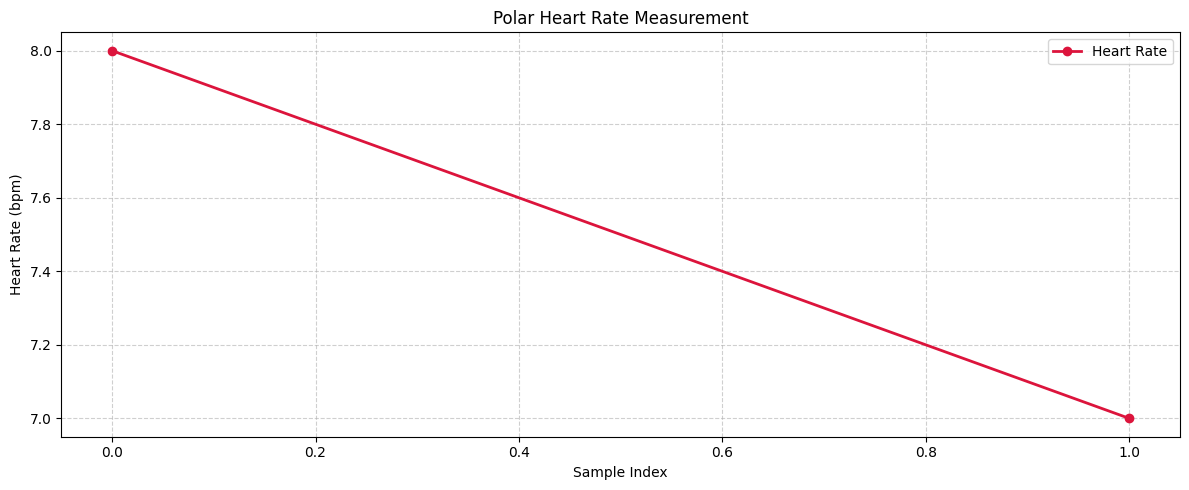

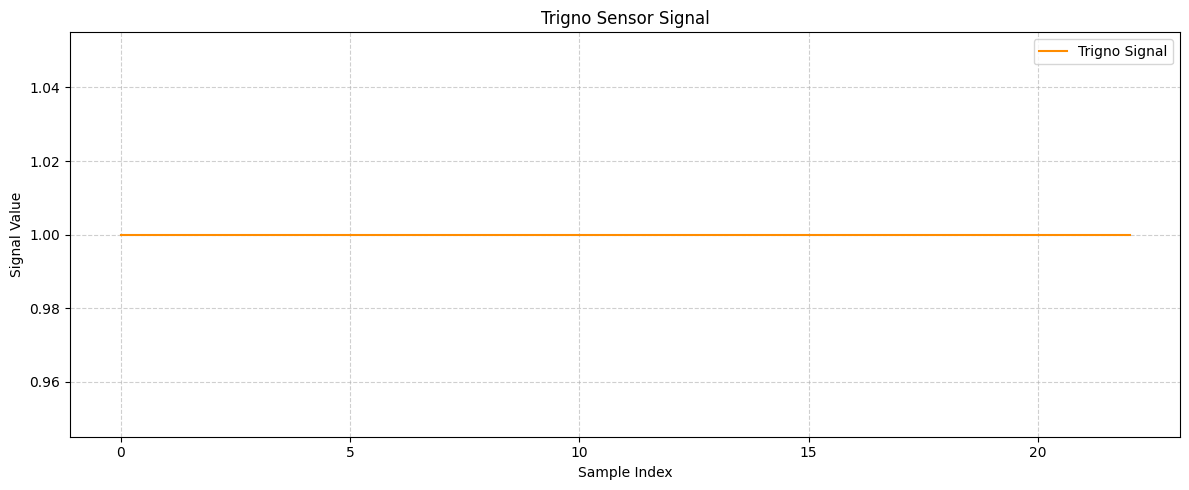

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Safely extract actual heart rate and times from dfpolar
polar_times = []
polar_hrs = []

for idx, row in dfpolar.iterrows():
    val = row.iloc[0]
    # Check if the row itself is a dictionary containing heart rate details
    if isinstance(val, dict):
        hr = val.get('heart_rate') or val.get('heartrate') or val.get('bpm') or val.get('value')
        t = val.get('time') or val.get('monotonic')
        if hr is not None:
            polar_hrs.append(hr)
            polar_times.append(t if t is not None else idx)
    else:
        # Check if the dataframe has structured columns we missed
        break

if len(polar_hrs) > 0:
    polar_y = polar_hrs
    polar_x = polar_times
else:
    # Fallback to standard columns
    polar_y = dfpolar['heart_rate'] if 'heart_rate' in dfpolar.columns else dfpolar.iloc[:, 0]
    polar_x = dfpolar['monotonic'] if 'monotonic' in dfpolar.columns else dfpolar.index

# --- Figure 1: Polar Heart Rate Data ---
plt.figure(figsize=(12, 5))
plt.plot(polar_x, polar_y, color='crimson', marker='o', linestyle='-', label='Heart Rate', linewidth=2)
plt.title('Polar Heart Rate Measurement')
plt.ylabel('Heart Rate (bpm)')
plt.xlabel('Time (s)' if 'monotonic' in dfpolar.columns or len(polar_times) > 0 else 'Sample Index')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# --- Figure 2: Trigno Data ---
plt.figure(figsize=(12, 5))
tringo_y = dftringo.iloc[:, 0]
tringo_x = dftringo['monotonic'] if 'monotonic' in dftringo.columns else dftringo.index
plt.plot(tringo_x, tringo_y, color='darkorange', label='Trigno Signal', linewidth=1.5)
plt.title('Trigno Sensor Signal')
plt.ylabel('Signal Value')
plt.xlabel('Time (s)' if 'monotonic' in dftringo.columns else 'Sample Index')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [26]:
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
import os
import re

def parse_cpet_excel_xml(file_path):
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            xml_text = f.read()

        # Sanitize unescaped ampersands to avoid XML parsing errors
        xml_text = re.sub(r'&(?!amp;|lt;|gt;|apos;|quot;)', '&amp;', xml_text)
        root = ET.fromstring(xml_text)
    except Exception as e:
        print(f"Error reading/parsing XML: {e}")
        return pd.DataFrame()

    # XML Spreadsheet 2003 Namespace
    ns = {'ss': 'urn:schemas-microsoft-com:office:spreadsheet'}

    # Find all Worksheet elements
    worksheets = root.findall('.//ss:Worksheet', ns)
    if not worksheets:
        print("No worksheets found.")
        return pd.DataFrame()

    # Use the first worksheet
    ws = worksheets[0]
    table = ws.find('ss:Table', ns)
    if table is None:
        print("No table found in the worksheet.")
        return pd.DataFrame()

    parsed_rows = []
    for row in table.findall('ss:Row', ns):
        row_data = []
        for cell in row.findall('ss:Cell', ns):
            data_elem = cell.find('ss:Data', ns)
            if data_elem is not None and data_elem.text is not None:
                val = data_elem.text.strip()
                try:
                    row_data.append(float(val))
                except ValueError:
                    row_data.append(val)
            else:
                row_data.append(None)
        parsed_rows.append(row_data)

    if not parsed_rows:
        return pd.DataFrame()

    # Identify the header row dynamically by searching all extracted rows for CPET keys
    header_idx = None
    for i, row in enumerate(parsed_rows):
        row_strs = [str(x).lower() for x in row if x is not None]
        # Search for key parameters typically present together in CPET summary/breath data headers
        if any('vo2' in s for s in row_strs) and any('vco2' in s for s in row_strs):
            header_idx = i
            break

    if header_idx is None:
        # Fallback to general keyword search
        for i, row in enumerate(parsed_rows):
            row_strs = [str(x).lower() for x in row if x is not None]
            if any('vo2' in s or 'vco2' in s or 've' in s for s in row_strs):
                header_idx = i
                break

    if header_idx is None:
        print("Could not find a header row containing gas exchange variables (VO2, VCO2, VE).")
        return pd.DataFrame()

    headers = [str(x).strip().replace('\n', ' ') if x is not None else f"Col_{idx}" for idx, x in enumerate(parsed_rows[header_idx])]
    data_rows = parsed_rows[header_idx + 1:]

    # Construct clean dataframe
    max_cols = len(headers)
    cleaned_rows = [r + [None] * (max_cols - len(r)) if len(r) < max_cols else r[:max_cols] for r in data_rows]
    df = pd.DataFrame(cleaned_rows, columns=headers)

    # Convert columns to numeric
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Filter out empty or metadata rows below the table
    df = df.dropna(subset=[col for col in df.columns if 'vo2' in col.lower() or 'vco2' in col.lower()], how='all')
    return df

# CPET file paths
cpet1_path = '/content/drive/MyDrive/DATA /NICK/CPET__D_F_2026.10.09_15.46.34_.xml'
cpet2_path = '/content/drive/MyDrive/DATA /NICK/CPET__D_Nick_2026.10.09_13.53.57_.xml'

for i, path in enumerate([cpet1_path, cpet2_path], start=1):
    if os.path.exists(path):
        print(f"\nProcessing CPET File {i}: {os.path.basename(path)}")
        df_cpet = parse_cpet_excel_xml(path)

        if not df_cpet.empty:
            print(f"Extracted variables: {list(df_cpet.columns)[:15]}")

            # Match columns case-insensitively
            vo2_col = next((c for c in df_cpet.columns if 'vo2' in c.lower() and 'rel' not in c.lower()),
                           next((c for c in df_cpet.columns if 'vo2' in c.lower()), None))
            vco2_col = next((c for c in df_cpet.columns if 'vco2' in c.lower()), None)
            ve_col = next((c for c in df_cpet.columns if 've' in c.lower() or 'vent' in c.lower()), None)
            time_col = next((c for c in df_cpet.columns if 't' == c.lower() or 'time' in c.lower() or 'sec' in c.lower()), None)

            t_axis = df_cpet[time_col] if time_col is not None else df_cpet.index
            t_label = time_col if time_col is not None else 'Samples'

            if vo2_col or vco2_col:
                plt.figure(figsize=(12, 5))
                if vo2_col:
                    plt.plot(t_axis, df_cpet[vo2_col], label=f'VO2 ({vo2_col})', color='blue', linewidth=2)
                    # Mark VO2 Max estimation if points exist
                    valid_vo2 = df_cpet[vo2_col].dropna()
                    if not valid_vo2.empty:
                        max_vo2_idx = valid_vo2.idxmax()
                        max_vo2_val = valid_vo2.max()
                        max_vo2_time = t_axis.loc[max_vo2_idx]
                        plt.scatter(max_vo2_time, max_vo2_val, color='darkblue', s=100, zorder=5, label=f'VO2 Max: {max_vo2_val:.1f}')
                if vco2_col:
                    plt.plot(t_axis, df_cpet[vco2_col], label=f'VCO2 ({vco2_col})', color='red', linewidth=1.5)

                plt.title(f'Oxygen Uptake & CO2 Production Over Time - File {i}')
                plt.xlabel(t_label)
                plt.ylabel('Gas Volume')
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend()
                plt.tight_layout()
                plt.show()

            if ve_col:
                plt.figure(figsize=(12, 4))
                plt.plot(t_axis, df_cpet[ve_col], label=f'Minute Ventilation ({ve_col})', color='green', linewidth=2)
                plt.title(f'Minute Ventilation (VE) over Time - File {i}')
                plt.xlabel(t_label)
                plt.ylabel('VE (L/min)')
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend()
                plt.tight_layout()
                plt.show()
        else:
            print(f"Could not load structured CPET columns from {os.path.basename(path)}")
    else:
        print(f"File does not exist: {path}")


Processing CPET File 1: CPET__D_F_2026.10.09_15.46.34_.xml
Could not load structured CPET columns from CPET__D_F_2026.10.09_15.46.34_.xml

Processing CPET File 2: CPET__D_Nick_2026.10.09_13.53.57_.xml
Could not load structured CPET columns from CPET__D_Nick_2026.10.09_13.53.57_.xml



Processing CPET File 1: CPET__D_F_2026.10.09_15.46.34_.xml
Selected Row 118 as Header: ['t', 'Phase', 'Marker', "V'O2", "V'O2/kg", "V'O2/HR", 'HR', 'WR', "V'E/V'O2", "V'E/V'CO2", 'RER', "V'E", 'VT', 'BF']
Loaded 1162 measurement samples successfully.


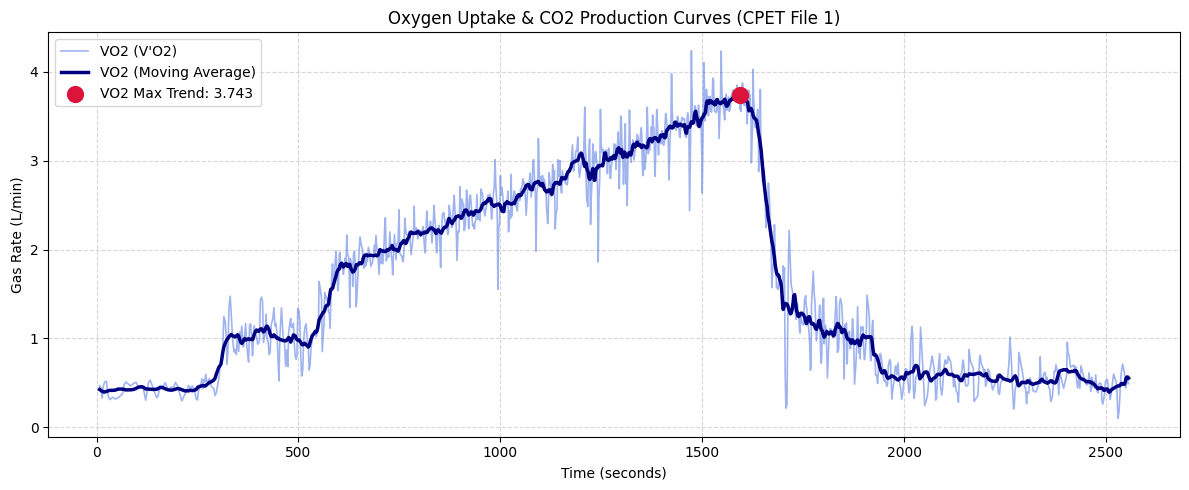

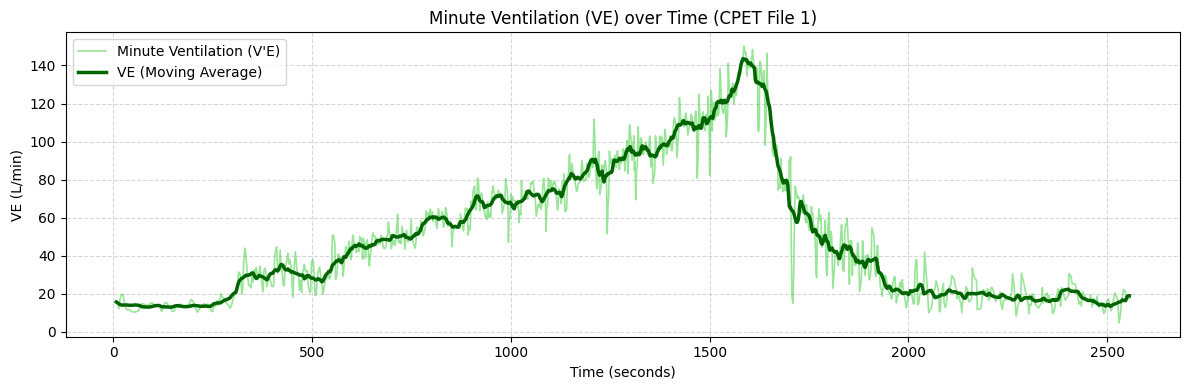


Processing CPET File 2: CPET__D_Nick_2026.10.09_13.53.57_.xml
Selected Row 118 as Header: ['t', 'Phase', 'Marker', "V'O2", "V'O2/kg", "V'O2/HR", 'HR', 'WR', "V'E/V'O2", "V'E/V'CO2", 'RER', "V'E", 'VT', 'BF']
Loaded 818 measurement samples successfully.


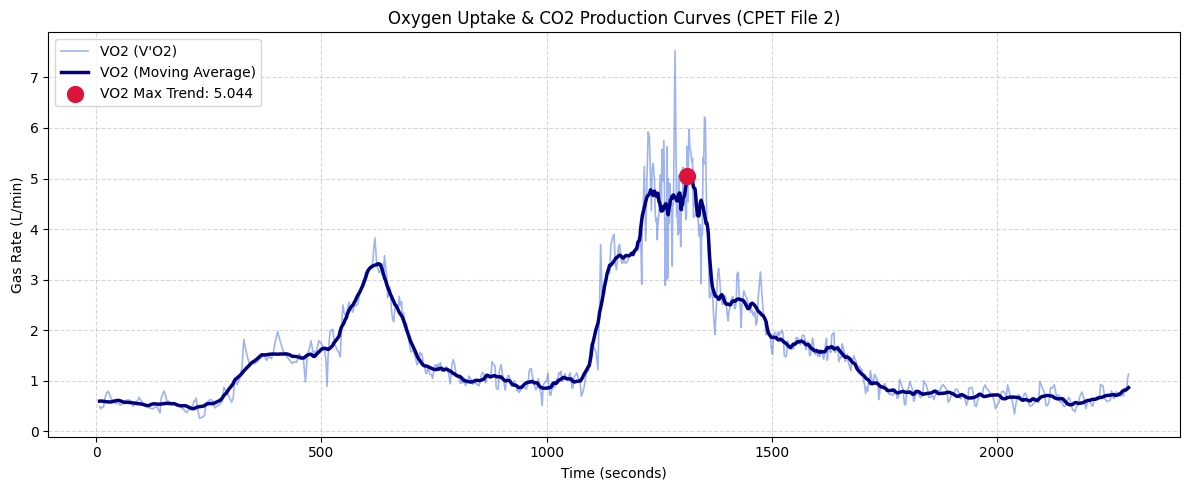

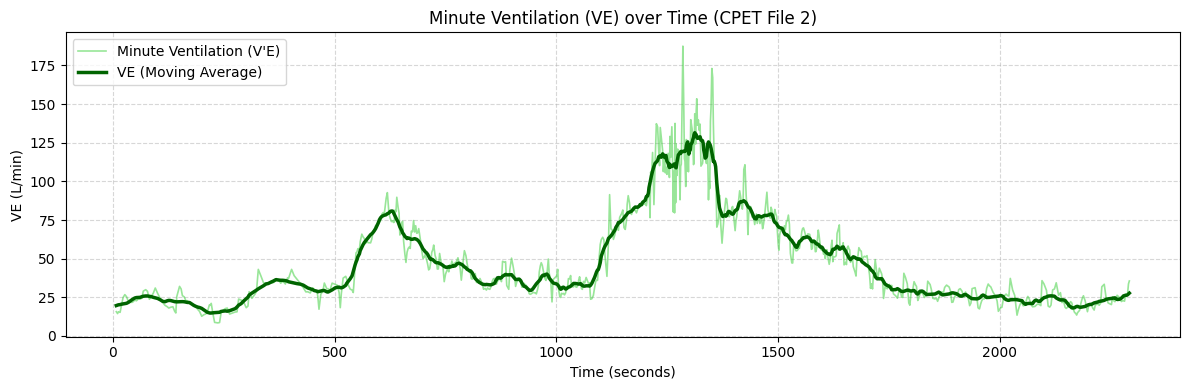

In [31]:
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import numpy as np

def parse_time_to_seconds(val):
    if pd.isna(val) or val is None:
        return np.nan
    val_str = str(val).strip()
    # Check if format is hh:mm:ss or mm:ss
    if ':' in val_str:
        parts = val_str.split(':')
        try:
            if len(parts) == 3:
                return float(parts[0]) * 3600 + float(parts[1]) * 60 + float(parts[2])
            elif len(parts) == 2:
                return float(parts[0]) * 60 + float(parts[1])
        except ValueError:
            pass
    try:
        return float(val_str)
    except ValueError:
        return np.nan

def parse_cpet_excel_xml(file_path):
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            xml_text = f.read()

        # Sanitize unescaped ampersands to avoid XML parsing errors
        xml_text = re.sub(r'&(?!amp;|lt;|gt;|apos;|quot;)', '&amp;', xml_text)
        root = ET.fromstring(xml_text)
    except Exception as e:
        print(f"Error reading/parsing XML: {e}")
        return pd.DataFrame()

    # XML Spreadsheet 2003 Namespace
    ns = {'ss': 'urn:schemas-microsoft-com:office:spreadsheet'}

    # Find all Worksheet elements
    worksheets = root.findall('.//ss:Worksheet', ns)
    if not worksheets:
        print("No worksheets found.")
        return pd.DataFrame()

    # Use the first worksheet
    ws = worksheets[0]
    table = ws.find('ss:Table', ns)
    if table is None:
        print("No table found in the worksheet.")
        return pd.DataFrame()

    parsed_rows = []
    for row in table.findall('ss:Row', ns):
        row_data = []
        for cell in row.findall('ss:Cell', ns):
            # Handle ss:Index attribute indicating skipped empty columns
            idx_attr = cell.get(f'{{{ns["ss"]}}}Index')
            if idx_attr:
                col_idx = int(idx_attr) - 1
                while len(row_data) < col_idx:
                    row_data.append(None)

            data_elem = cell.find('ss:Data', ns)
            if data_elem is not None and data_elem.text is not None:
                val = data_elem.text.strip()
                row_data.append(val)
            else:
                row_data.append(None)
        parsed_rows.append(row_data)

    if not parsed_rows:
        return pd.DataFrame()

    # Identify the header row dynamically
    header_idx = None
    for i, row in enumerate(parsed_rows):
        row_strs = [str(x).strip() for x in row if x is not None]
        if any(h == "V'O2" or h == "VO2" for h in row_strs) and any(h == "t" or h == "Time" for h in row_strs):
            header_idx = i
            break

    if header_idx is None:
        for i, row in enumerate(parsed_rows):
            row_strs = [str(x).lower() for x in row if x is not None]
            if any("v'o2" in s for s in row_strs) and any("v'co2" in s for s in row_strs):
                header_idx = i
                break

    if header_idx is None:
        print("Could not find the true measurement table header row.")
        return pd.DataFrame()

    print(f"Selected Row {header_idx} as Header: {parsed_rows[header_idx]}")
    headers = [str(x).strip().replace('\n', ' ') if x is not None else f"Col_{idx}" for idx, x in enumerate(parsed_rows[header_idx])]
    data_rows = parsed_rows[header_idx + 1:]

    # Construct clean dataframe
    max_cols = len(headers)
    cleaned_rows = [r + [None] * (max_cols - len(r)) if len(r) < max_cols else r[:max_cols] for r in data_rows]
    df = pd.DataFrame(cleaned_rows, columns=headers)

    # Identify columns
    time_col_key = next((c for c in df.columns if c.strip() == 't' or 'time' in c.lower()), None)
    vo2_col_key = next((c for c in df.columns if "v'o2" in c.lower() or "vo2" in c.lower()), None)

    # Convert time to cumulative seconds
    if time_col_key:
        df[time_col_key] = df[time_col_key].apply(parse_time_to_seconds)

    # Convert other columns to numeric
    for col in df.columns:
        if col != time_col_key:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    # Keep only rows with valid numeric Time and VO2
    if time_col_key and vo2_col_key:
        df = df.dropna(subset=[time_col_key, vo2_col_key])
    return df

# CPET file paths
cpet1_path = '/content/drive/MyDrive/DATA /NICK/CPET__D_F_2026.10.09_15.46.34_.xml'
cpet2_path = '/content/drive/MyDrive/DATA /NICK/CPET__D_Nick_2026.10.09_13.53.57_.xml'

for i, path in enumerate([cpet1_path, cpet2_path], start=1):
    if os.path.exists(path):
        print(f"\nProcessing CPET File {i}: {os.path.basename(path)}")
        df_cpet = parse_cpet_excel_xml(path)

        if not df_cpet.empty:
            print(f"Loaded {len(df_cpet)} measurement samples successfully.")

            # Pinpoint exact columns to avoid ratios
            vo2_col = next((c for c in df_cpet.columns if c.strip() in ["V'O2", "VO2"]), None)
            vco2_col = next((c for c in df_cpet.columns if c.strip() in ["V'CO2", "VCO2"]), None)
            ve_col = next((c for c in df_cpet.columns if c.strip() in ["V'E", "VE"]), None)
            time_col = next((c for c in df_cpet.columns if c.strip() == 't' or 'time' in c.lower()), None)

            t_axis = df_cpet[time_col]
            t_label = "Time (seconds)"

            if vo2_col or vco2_col:
                plt.figure(figsize=(12, 5))
                if vo2_col:
                    plt.plot(t_axis, df_cpet[vo2_col], label=f'VO2 ({vo2_col})', color='royalblue', linewidth=1.2, alpha=0.5)
                    # Smooth curves to find a reliable VO2 Max trend
                    smoothed_vo2 = df_cpet[vo2_col].rolling(window=15, center=True, min_periods=1).mean()
                    plt.plot(t_axis, smoothed_vo2, label='VO2 (Moving Average)', color='navy', linewidth=2.5)

                    valid_vo2 = smoothed_vo2.dropna()
                    if not valid_vo2.empty:
                        max_vo2_idx = valid_vo2.idxmax()
                        max_vo2_val = valid_vo2.max()
                        max_vo2_time = t_axis.loc[max_vo2_idx]
                        plt.scatter(max_vo2_time, max_vo2_val, color='crimson', s=130, zorder=6, label=f'VO2 Max Trend: {max_vo2_val:.3f}')

                if vco2_col:
                    plt.plot(t_axis, df_cpet[vco2_col], label=f'VCO2 ({vco2_col})', color='tomato', linewidth=1.2, alpha=0.5)
                    smoothed_vco2 = df_cpet[vco2_col].rolling(window=15, center=True, min_periods=1).mean()
                    plt.plot(t_axis, smoothed_vco2, label='VCO2 (Moving Average)', color='darkred', linewidth=2)

                plt.title(f'Oxygen Uptake & CO2 Production Curves (CPET File {i})')
                plt.xlabel(t_label)
                plt.ylabel('Gas Rate (L/min)')
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend(loc='upper left')
                plt.tight_layout()
                plt.show()

            if ve_col:
                plt.figure(figsize=(12, 4))
                plt.plot(t_axis, df_cpet[ve_col], label=f'Minute Ventilation ({ve_col})', color='limegreen', linewidth=1.2, alpha=0.5)
                smoothed_ve = df_cpet[ve_col].rolling(window=15, center=True, min_periods=1).mean()
                plt.plot(t_axis, smoothed_ve, label='VE (Moving Average)', color='darkgreen', linewidth=2.5)

                plt.title(f'Minute Ventilation (VE) over Time (CPET File {i})')
                plt.xlabel(t_label)
                plt.ylabel('VE (L/min)')
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend(loc='upper left')
                plt.tight_layout()
                plt.show()
        else:
            print(f"Could not load structured CPET columns from {os.path.basename(path)}")
    else:
         print(f"File does not exist: {path}")